# Cloud fraction analysis

For each collocation case (filtered to valid IAGOS temperature & RHL, a contrail-formation
annotation, and a defined PS efficiency), look up the ERA5 **fraction of cloud cover**
at the aircraft's time, longitude, latitude and altitude from the per-collocation
`arco-era5-cc.nc4` file.

Then report how many cases have a non-zero cloud fraction and the distribution of those
non-zero values.

In [1]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
# Load collocations and apply filters
df = pd.read_csv('../data/landsat_sentinel_collocations_20260216.csv', comment='#')
df = df[df["air_temperature_iagos_validity"] <= 0]
df = df[df["rhl_iagos_validity"] <= 0]
df = df[df["contrail_formation"].notna()]
df = df[df["efficiency_PS_IAGOS"].notna()]
print(f"Number of cases after filtering: {len(df)}")

Number of cases after filtering: 543


In [3]:
COLLOC_BASE = "../data/collocations"


def cloud_fraction_for_row(row):
    """ERA5 fraction of cloud cover at the aircraft's time, lon, lat and altitude.

    Reads the per-collocation ``arco-era5-cc.nc4`` file, which holds
    ``fraction_of_cloud_cover`` on (longitude, latitude, level, time). The ``level``
    dimension carries an ``altitude`` coordinate, so we pick the nearest lon/lat grid
    cell and time, then the model level whose altitude is closest to the aircraft.
    """
    path = os.path.join(COLLOC_BASE, row["path"], "arco-era5-cc.nc4")
    if not os.path.exists(path):
        return np.nan

    with xr.open_dataset(path) as ds:
        t = pd.to_datetime(row["sensing_time"]).tz_localize(None).to_datetime64()
        cf = ds["fraction_of_cloud_cover"].sel(
            longitude=row["longitude"],
            latitude=row["latitude"],
            method="nearest",
        ).sel(time=t, method="nearest")

        # nearest model level by altitude
        alt = ds["altitude"].values  # one value per level
        level_idx = int(np.abs(alt - row["altitude"]).argmin())
        return float(cf.isel(level=level_idx).values)


df = df.copy()
df["cloud_fraction"] = df.apply(cloud_fraction_for_row, axis=1)
df["cloud_fraction"].describe()

count    543.000000
mean       0.082335
std        0.219289
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: cloud_fraction, dtype: float64

In [4]:
cf = df["cloud_fraction"].dropna().values
nonzero = cf[cf > 0]

print(f"Total cases:            {len(cf)}")
print(f"Non-zero cloud cover:   {len(nonzero)}")
print(f"Zero cloud cover:       {int((cf == 0).sum())}")
print()
print("Distribution of non-zero cloud fraction:")
print(f"  min    {nonzero.min():.4f}")
print(f"  p10    {np.percentile(nonzero, 10):.4f}")
print(f"  p25    {np.percentile(nonzero, 25):.4f}")
print(f"  median {np.median(nonzero):.4f}")
print(f"  mean   {nonzero.mean():.4f}")
print(f"  p75    {np.percentile(nonzero, 75):.4f}")
print(f"  p90    {np.percentile(nonzero, 90):.4f}")
print(f"  max    {nonzero.max():.4f}")

Total cases:            543
Non-zero cloud cover:   134
Zero cloud cover:       409

Distribution of non-zero cloud fraction:
  min    0.0003
  p10    0.0064
  p25    0.0268
  median 0.1911
  mean   0.3336
  p75    0.6146
  p90    0.8394
  max    1.0000


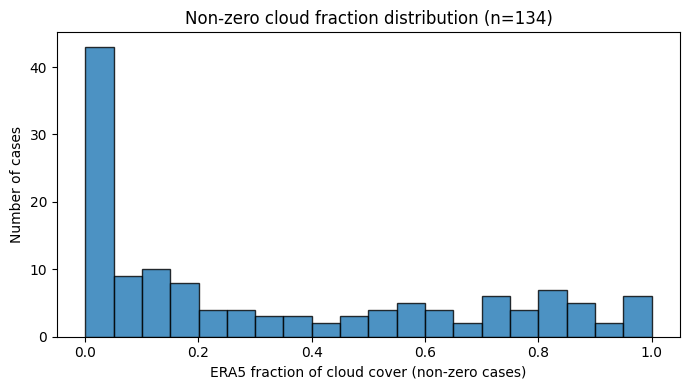

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nonzero, bins=20, edgecolor="k", alpha=0.8)
ax.set_xlabel("ERA5 fraction of cloud cover (non-zero cases)")
ax.set_ylabel("Number of cases")
ax.set_title(f"Non-zero cloud fraction distribution (n={len(nonzero)})")
plt.tight_layout()
plt.show()

## Splitting the ERA5 humidity into an in-cloud and a clear-sky part

`rhi_era5` / `rhl_era5` are **grid-box means**: ERA5 carries one specific humidity for a
cell that is a fraction `cc` cloud and `1 - cc` clear air,

$$\bar{q} = cc \cdot q_\mathrm{cloud} + (1 - cc)\, q_\mathrm{clear}.$$

Temperature and pressure are uniform within the grid box, so the saturation humidity is
the same everywhere in it and the identical linear split holds for relative humidity.
The IFS cloud scheme keeps the cloudy fraction exactly at ice saturation
($\mathrm{RH}_i = 100\,\%$ for these temperatures), which leaves

$$\mathrm{RH}_{i,\mathrm{cloud}} = 100\,\%, \qquad
  \mathrm{RH}_{i,\mathrm{clear}} = \frac{\overline{\mathrm{RH}_i} - cc}{1 - cc}.$$

Two consequences worth noting before looking at the numbers:

* the difference is $\mathrm{RH}_{i,\mathrm{clear}} - \overline{\mathrm{RH}_i} =
  \frac{cc}{1-cc}\left(\overline{\mathrm{RH}_i} - 1\right)$, so the clear-sky value is
  **higher** than the grid mean whenever the grid box is ice-supersaturated and lower
  when it is subsaturated;
* the sign flips exactly at ice saturation, so no case can move from subsaturated to
  supersaturated (or back) through this correction — only its magnitude changes.

RH w.r.t. liquid follows from the same numbers via
$\mathrm{RH}_l = \mathrm{RH}_i \cdot e_{\mathrm{sat},i}(T) / e_{\mathrm{sat},l}(T)$.

In [6]:
from iagos_toolkit.weather.thermo import (
    COEFFS_ICE_ALDUCHOV,
    COEFFS_WATER_BUCK,
    saturation_vapor_pressure_era5,
)

cc = df["cloud_fraction"]

# Ice: cloudy fraction sits at saturation, clear fraction takes the remainder.
df["rhi_era5_in_cloud"] = 1.0
df["rhi_era5_clear"] = ((df["rhi_era5"] - cc) / (1.0 - cc)).where(cc < 1)

# Same split expressed w.r.t. liquid water.
esat_ratio = saturation_vapor_pressure_era5(
    df["air_temperature_era5"], COEFFS_ICE_ALDUCHOV
) / saturation_vapor_pressure_era5(df["air_temperature_era5"], COEFFS_WATER_BUCK)
df["rhl_era5_in_cloud"] = esat_ratio
df["rhl_era5_clear"] = df["rhi_era5_clear"] * esat_ratio

cloudy = df[df["cloud_fraction"] > 0]

summary = pd.DataFrame(
    [
        {
            "": name,
            "grid-box mean [%]": 100 * cloudy[grid].mean(),
            "in cloud [%]": 100 * cloudy[in_cloud].mean(),
            "clear sky [%]": 100 * cloudy[clear].mean(),
        }
        for name, grid, in_cloud, clear in [
            ("RHi", "rhi_era5", "rhi_era5_in_cloud", "rhi_era5_clear"),
            ("RHL", "rhl_era5", "rhl_era5_in_cloud", "rhl_era5_clear"),
        ]
    ]
).set_index("")

print(f"Cases with cc > 0: {len(cloudy)}   mean cc = {cloudy['cloud_fraction'].mean():.3f}")
print(f"cc == 1 (clear-sky part undefined): {int((cloudy['cloud_fraction'] == 1).sum())}")
summary.round(2)

Cases with cc > 0: 134   mean cc = 0.334
cc == 1 (clear-sky part undefined): 2


,grid-box mean [%],in cloud [%],clear sky [%]
,,,
RHi,79.88,100.00,75.85
RHL,51.13,64.89,48.46


In [7]:
# How far does the RH move away from the grid-box mean, for the cc > 0 cases?
d_cloud = 100 * (cloudy["rhi_era5_in_cloud"] - cloudy["rhi_era5"])
d_clear = 100 * (cloudy["rhi_era5_clear"] - cloudy["rhi_era5"])

supersat = cloudy["rhi_era5"] > 1


def report(label, delta, mask=None):
    d = delta if mask is None else delta[mask]
    d = d.dropna()
    print(
        f"{label:<44s} n={len(d):3d}  mean {d.mean():+7.2f} pp   median {d.median():+7.2f} pp"
        f"   [{d.min():+7.2f}, {d.max():+7.2f}]"
    )


print("Change in RHi relative to the ERA5 grid-box mean (percentage points)\n")
report("in-cloud air (all cc > 0)", d_cloud)
report("clear-sky air (all cc > 0)", d_clear)
print()
report("clear sky, grid box supersaturated (RHi > 100%)", d_clear, supersat)
report("clear sky, grid box subsaturated  (RHi < 100%)", d_clear, ~supersat)
print()
print(
    f"Supersaturated & cloudy subset: mean RHi {100 * cloudy.loc[supersat, 'rhi_era5'].mean():.2f}%"
    f"  ->  {100 * cloudy.loc[supersat, 'rhi_era5_clear'].mean():.2f}% in the clear part"
    f"  (mean cc = {cloudy.loc[supersat, 'cloud_fraction'].mean():.3f})"
)

# Sanity check: the split can only stay physical while the grid-mean RHi exceeds cc.
bad = cloudy["rhi_era5_clear"] < 0
print(
    f"\nCases with a negative clear-sky RHi (grid-mean RHi < cc): {int(bad.sum())}"
    " - cc is taken at the nearest model level while rhi_era5 is interpolated,"
    " so the two can disagree in near-overcast boxes."
)
print(
    "Clipping those at 0 gives a mean clear-sky change of "
    f"{(100 * (cloudy['rhi_era5_clear'].clip(lower=0) - cloudy['rhi_era5'])).mean():+.2f} pp."
)

Change in RHi relative to the ERA5 grid-box mean (percentage points)

in-cloud air (all cc > 0)                    n=134  mean  +20.12 pp   median   +8.75 pp   [ -31.11,  +89.10]
clear-sky air (all cc > 0)                   n=132  mean   -3.73 pp   median   -0.57 pp   [-137.79,  +50.60]

clear sky, grid box supersaturated (RHi > 100%) n= 38  mean   +8.42 pp   median   +5.38 pp   [  +0.00,  +50.60]
clear sky, grid box subsaturated  (RHi < 100%) n= 94  mean   -8.64 pp   median   -1.45 pp   [-137.79,   -0.01]

Supersaturated & cloudy subset: mean RHi 104.91%  ->  113.57% in the clear part  (mean cc = 0.599)

Cases with a negative clear-sky RHi (grid-mean RHi < cc): 3 - cc is taken at the nearest model level while rhi_era5 is interpolated, so the two can disagree in near-overcast boxes.
Clipping those at 0 gives a mean clear-sky change of -3.08 pp.
